# Phase 1: Environment Setup & Raw Schema Inspection

### Objective
Initialize the processing environment and set up memory-efficient data scanning for the LendingClub dataset using Polars LazyFrames.

### Technical Rationale
The raw LendingClub CSV is multi-gigabyte containing over 2 million rows and 100+ feature columns. Standard Pandas `read_csv` attempts to load the entire payload into RAM at once, leading to excessive memory pressure or out-of-memory (OOM) crashes.
- We use `pl.scan_csv` to establish a query plan to explore the dataset

In [1]:
import polars as pl

# Polars display config
pl.Config.set_tbl_rows(15)
pl.Config.set_tbl_cols(12)

# File path 
DATA_PATH = "/home/mike/Documents/work/DS/projects/credit-risk/data/raw/accepted_2007_to_2018Q4.csv"

# Step 1: Create the LazyFrame query graph
lazy_df = pl.scan_csv(
    DATA_PATH,
    infer_schema_length=10000,
    ignore_errors=True
)

In [2]:
lazy_df

In [3]:
schema = lazy_df.collect_schema()
total_columns = len(schema.names())

print(f"Total Columns Loaded: {total_columns}")

Total Columns Loaded: 151


In [4]:
lazy_df.head(5).collect()

id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,…,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
i64,str,f64,f64,f64,str,…,str,str,str,f64,f64,f64
68407277,null,3600.0,3600.0,3600.0,""" 36 months""",…,null,null,null,null,null,null
68355089,null,24700.0,24700.0,24700.0,""" 36 months""",…,null,null,null,null,null,null
68341763,null,20000.0,20000.0,20000.0,""" 60 months""",…,null,null,null,null,null,null
66310712,null,35000.0,35000.0,35000.0,""" 60 months""",…,null,null,null,null,null,null
68476807,null,10400.0,10400.0,10400.0,""" 60 months""",…,null,null,null,null,null,null


# Step 1.2: Data Sanitization, Target Engineering & Leakage Audit

### Objectives
1. **Schema Sanitization:** Coerce the `id` column to `pl.String` and drop malformed/corrupted rows (e.g., rogue header strings or footer metadata injected during CSV generation).
2. **Deterministic Target Definition:** Isolate historical loan outcomes into binary default indicator (`is_default`).
3. **Data Leakage Audit:** Strip out post-origination collection variables (e.g., `recoveries`, `total_rec_prncp`, `last_pymnt_d`) that contain future information inaccessible at loan underwriting time.

### Target Mapping Rules
- **Default (`1`):** `Charged Off`, `Default`, `Late (31-120 days)`, `Does not meet the credit policy. Status:Charged Off`
- **Non-Default (`0`):** `Fully Paid`, `Does not meet the credit policy. Status:Fully Paid`
- **Exclusions:** `Current`, `In Grace Period`, `Late (16-30 days)` (indeterminate performance window)

In [5]:
# Empirical Discovery: Scan unique loan statuses and their exact counts
loan_status_distribution = (
    lazy_df
    # Ensure ID is coerced to string and rogue rows are dropped first
    .with_columns(pl.col("id").cast(pl.String, strict=False).alias("id"))
    .filter(pl.col("id").is_not_null())
    .filter(pl.col("id").str.contains(r"^\d+$"))
    
    # Group and count occurrences across the entire raw dataset
    .group_by("loan_status")
    .agg(pl.len().alias("count"))
    .sort("count", descending=True)
    .collect()
)

print("Empirical Unique loan_status Distribution:")
print(loan_status_distribution)

Empirical Unique loan_status Distribution:
shape: (9, 2)
┌─────────────────────────────────┬─────────┐
│ loan_status                     ┆ count   │
│ ---                             ┆ ---     │
│ str                             ┆ u32     │
╞═════════════════════════════════╪═════════╡
│ Fully Paid                      ┆ 1076751 │
│ Current                         ┆ 878317  │
│ Charged Off                     ┆ 268559  │
│ Late (31-120 days)              ┆ 21467   │
│ In Grace Period                 ┆ 8436    │
│ Late (16-30 days)               ┆ 4349    │
│ Does not meet the credit polic… ┆ 1988    │
│ Does not meet the credit polic… ┆ 761     │
│ Default                         ┆ 40      │
└─────────────────────────────────┴─────────┘


In [6]:
#rows with text in the id column
total_raw_rows = lazy_df.select(pl.len()).collect().item()

sanitized_row_count = (
    lazy_df
    .with_columns(pl.col("id").cast(pl.String, strict=False).alias("id"))
    .filter(pl.col("id").is_not_null())
    .filter(pl.col("id").str.contains(r"^\d+$"))
    .select(pl.len())
    .collect()
    .item()
)

dropped_rows = total_raw_rows - sanitized_row_count
print(f"Total Raw Rows in CSV: {total_raw_rows:,}")
print(f"Rows After ID Sanitization: {sanitized_row_count:,}")
print(f"Dropped Malformed/Rogue Rows: {dropped_rows:,} ({(dropped_rows / total_raw_rows):.4%})")

Total Raw Rows in CSV: 2,260,701
Rows After ID Sanitization: 2,260,668
Dropped Malformed/Rogue Rows: 33 (0.0015%)


In [7]:
# Discover how loan statuses are distributed temporally across issue years
status_by_year_discovery = (
    lazy_df
    .with_columns(pl.col("id").cast(pl.String, strict=False).alias("id"))
    .filter(pl.col("id").is_not_null())
    .filter(pl.col("id").str.contains(r"^\d+$"))
    # Parse year from issue_d (format like Dec-2015)
    .with_columns(pl.col("issue_d").str.to_date("%b-%Y", strict=False).dt.year().alias("issue_year"))
    .group_by(["issue_year", "loan_status"])
    .agg(pl.len().alias("count"))
    .sort(["issue_year", "count"], descending=[False, True])
    .collect()
)

print(status_by_year_discovery)

shape: (60, 3)
┌────────────┬─────────────────────────────────┬────────┐
│ issue_year ┆ loan_status                     ┆ count  │
│ ---        ┆ ---                             ┆ ---    │
│ i32        ┆ str                             ┆ u32    │
╞════════════╪═════════════════════════════════╪════════╡
│ 2007       ┆ Does not meet the credit polic… ┆ 239    │
│ 2007       ┆ Fully Paid                      ┆ 206    │
│ 2007       ┆ Does not meet the credit polic… ┆ 113    │
│ 2007       ┆ Charged Off                     ┆ 45     │
│ 2008       ┆ Fully Paid                      ┆ 1315   │
│ 2008       ┆ Does not meet the credit polic… ┆ 582    │
│ 2008       ┆ Does not meet the credit polic… ┆ 249    │
│ 2008       ┆ Charged Off                     ┆ 247    │
│ …          ┆ …                               ┆ …      │
│ 2018       ┆ Current                         ┆ 427181 │
│ 2018       ┆ Fully Paid                      ┆ 47444  │
│ 2018       ┆ Charged Off                     ┆ 8867   │

# Step 1.3: Target Mapping & Temporal Out-of-Time (OOT) Split

### Objective
1. **Target Engineering:** Map our empirically verified statuses into a binary target (`is_default`).
   - `is_default = 1`: `Charged Off`, `Default`, `Late (31-120 days)`
   - `is_default = 0`: `Fully Paid`, along with legacy credit policy exceptions that resolved successfully.
   - *Exclusions:* Drop indeterminate active states (`Current`, `In Grace Period`, `Late (16-30 days)`).
2. **Temporal Partitioning:** Split the historical data before and after 2018 to create an Out-of-Time (OOT) validation set, preventing future data leakage.

In [9]:
# 1. Define empirical target mappings based on discovery
DEFAULT_STATUSES = [
    "Charged Off",
    "Default",
    "Late (31-120 days)",
    "Does not meet the credit policy. Status:Charged Off"
]

PAID_STATUSES = [
    "Fully Paid",
    "Does not meet the credit policy. Status:Fully Paid"
]

# 2. Execute target mapping and temporal feature extraction on the LazyFrame
modeled_lazy = (
    lazy_df
    # Sanitize ID
    .with_columns(pl.col("id").cast(pl.String, strict=False).alias("id"))
    .filter(pl.col("id").is_not_null())
    .filter(pl.col("id").str.contains(r"^\d+$"))
    
    # Filter to only include resolved states
    .filter(pl.col("loan_status").is_in(DEFAULT_STATUSES + PAID_STATUSES))
    
    # Create binary target
    .with_columns(
        pl.when(pl.col("loan_status").is_in(DEFAULT_STATUSES))
        .then(1)
        .otherwise(0)
        .alias("is_default")
    )
    
    # Extract issue year for temporal split
    .with_columns(
        pl.col("issue_d").str.to_date("%b-%Y", strict=False).dt.year().alias("issue_year")
    )
)

# 3. Collect into memory for partitioning
processed_df = modeled_lazy.collect()

# 4. Enforce OOT split (e.g., Development: < 2018, OOT Evaluation: >= 2018)
train_df = processed_df.filter(pl.col("issue_year") < 2018)
oot_df = processed_df.filter(pl.col("issue_year") >= 2018)

print(f"Total Processed Resolved Loans: {processed_df.height:,}")
print(f"In-Time Training Set (< 2018): {train_df.height:,} rows | Default Rate: {train_df['is_default'].mean():.2%}")
print(f"Out-of-Time Evaluation Set (>= 2018): {oot_df.height:,} rows | Default Rate: {oot_df['is_default'].mean():.2%}")

Total Processed Resolved Loans: 1,369,566
In-Time Training Set (< 2018): 1,306,027 rows | Default Rate: 21.04%
Out-of-Time Evaluation Set (>= 2018): 63,539 rows | Default Rate: 25.33%


# Phase 2: Feature Engineering & Missingness Discovery

### Objective
Profile the training set feature space for null rates and structural missingness. We will identify which columns are densely populated versus those that require omission or specialized imputation strategies.

In [10]:
# Calculate null counts and null percentages across all columns in the training set
missingness_df = (
    train_df
    .select([
        (pl.col(col).null_count() / pl.len()).alias(col) 
        for col in train_df.columns
    ])
    .transpose(include_header=True, header_name="feature", column_names=["null_pct"])
    .sort("null_pct", descending=True)
)

print("Top 20 Columns with Highest Missingness:")
print(missingness_df.head(20))

Top 20 Columns with Highest Missingness:
shape: (20, 2)
┌─────────────────────────────────┬──────────┐
│ feature                         ┆ null_pct │
│ ---                             ┆ ---      │
│ str                             ┆ f64      │
╞═════════════════════════════════╪══════════╡
│ member_id                       ┆ 1.0      │
│ sec_app_mths_since_last_major_… ┆ 0.996511 │
│ orig_projected_additional_accr… ┆ 0.996144 │
│ hardship_type                   ┆ 0.994515 │
│ hardship_reason                 ┆ 0.994515 │
│ hardship_status                 ┆ 0.994515 │
│ deferral_term                   ┆ 0.994515 │
│ hardship_amount                 ┆ 0.994515 │
│ …                               ┆ …        │
│ hardship_loan_status            ┆ 0.994515 │
│ hardship_payoff_balance_amount  ┆ 0.994515 │
│ hardship_last_payment_amount    ┆ 0.994515 │
│ sec_app_revol_util              ┆ 0.990647 │
│ revol_bal_joint                 ┆ 0.990492 │
│ sec_app_fico_range_low          ┆ 0.990491 │
│ se

# Step 2.1: Feature Pruning & Leakage Prevention

### Objective
Drop columns exhibiting extreme missingness (>90% null) and strip out post-origination leakage features to ensure our feature store contains only variables known at the exact moment of loan underwriting.

In [11]:
# 1. Identify columns with > 90% missingness in the training set
high_null_cols = (
    missingness_df
    .filter(pl.col("null_pct") > 0.90)
    .get_column("feature")
    .to_list()
)

# 2. Define known post-origination leakage columns to strip
LEAKAGE_COLUMNS = [
    "collection_recovery_fee", "funded_amnt", "funded_amnt_inv", 
    "issue_d", "last_credit_pull_d", "last_fico_band_high", "last_fico_band_low",
    "last_pymnt_amnt", "last_pymnt_d", "next_pymnt_d", "out_prncp",
    "out_prncp_inv", "recoveries", "total_pymnt", "total_pymnt_inv",
    "total_rec_int", "total_rec_late_fee", "total_rec_prncp",
    "policy_code", "url", "id", "emp_title", "title" # Drop text/ID identifiers
]

# Combine columns to drop
columns_to_drop = list(set(high_null_cols + LEAKAGE_COLUMNS))

print(f"Total features originally: {train_df.width}")
print(f"Total columns targeted for removal (high nulls + leakage/identifiers): {len(columns_to_drop)}")

Total features originally: 153
Total columns targeted for removal (high nulls + leakage/identifiers): 61


In [12]:
# 3. Filter feature set for train and oot sets (retaining 'is_default' and 'issue_year')
final_train_df = train_df.drop([c for c in columns_to_drop if c in train_df.columns])
final_oot_df = oot_df.drop([c for c in columns_to_drop if c in oot_df.columns])

print(f"Final feature count for modeling: {final_train_df.width - 2}") # excluding target and year

Final feature count for modeling: 92


# Phase 3: Categorical Encoding & Baseline Model Training

### Objective
1. Identify remaining categorical string columns in our 92-feature set.
2. Encode categorical variables into integer/ordinal formats suitable for tree-based algorithms.
3. Separate feature matrices ($X$) and target vectors ($y$) for both training and OOT evaluation sets.

In [13]:
# 1. Identify remaining string columns in the training set (excluding target and year)
categorical_cols = [
    col for col, dtype in zip(final_train_df.columns, final_train_df.dtypes) 
    if dtype == pl.Utf8 and col not in ["is_default"]
]

print(f"Identified Categorical Columns to Encode: {categorical_cols}")

Identified Categorical Columns to Encode: ['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'loan_status', 'pymnt_plan', 'purpose', 'zip_code', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'application_type', 'hardship_flag', 'disbursement_method', 'debt_settlement_flag']


In [14]:
# 2. Convert categorical columns to categorical dtype / integer codes in Polars
# Using Polars .cast(pl.Categorical).to_physical() for efficient tree-friendly encoding
encoded_train_df = final_train_df.with_columns([
    pl.col(col).cast(pl.Categorical).to_physical().alias(col)
    for col in categorical_cols
])

encoded_oot_df = final_oot_df.with_columns([
    pl.col(col).cast(pl.Categorical).to_physical().alias(col)
    for col in categorical_cols
])

# 3. Separate Features (X) and Target (y)
feature_cols = [c for c in encoded_train_df.columns if c not in ["is_default", "issue_year"]]

X_train = encoded_train_df.select(feature_cols).to_numpy()
y_train = encoded_train_df.select("is_default").to_numpy().ravel()

X_oot = encoded_oot_df.select(feature_cols).to_numpy()
y_oot = encoded_oot_df.select("is_default").to_numpy().ravel()

print(f"Training Matrix Shape (X_train): {X_train.shape}")
print(f"OOT Evaluation Matrix Shape (X_oot): {X_oot.shape}")

Training Matrix Shape (X_train): (1306027, 92)
OOT Evaluation Matrix Shape (X_oot): (63539, 92)


# Phase 3.1: XGBoost Baseline Model Training & OOT Evaluation

### Objective
1. Ensure `loan_status` and any text variables are strictly stripped from the feature matrix to prevent target leakage.
2. Train an XGBoost classifier on the pre-2018 training dataset (`X_train`, `y_train`).
3. Evaluate predictive power on the Out-of-Time holdout set (`X_oot`, `y_oot`) using **ROC-AUC / Gini** and the **Kolmogorov-Smirnov (KS) statistic**—the gold standards in credit risk scorecard validation.

In [16]:
from sklearn.metrics import roc_auc_score
import numpy as np
import xgboost as xgb

# 1. Ensure loan_status is explicitly dropped from features if present
strict_feature_cols = [
    c for c in feature_cols 
    if c not in ["loan_status", "is_default", "issue_year"]
]

X_train_final = encoded_train_df.select(strict_feature_cols).to_numpy()
X_oot_final = encoded_oot_df.select(strict_feature_cols).to_numpy()

print(f"Strict Feature Count for Modeling: {len(strict_feature_cols)}")

# 2. Configure and train XGBoost classifier
# Using optimized parameters for tabular credit risk modeling
params = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "tree_method": "hist" # Fast histogram-optimized splitting for large datasets
}

dtrain = xgb.DMatrix(X_train_final, label=y_train, feature_names=strict_feature_cols)
doot = xgb.DMatrix(X_oot_final, label=y_oot, feature_names=strict_feature_cols)

# Train with early stopping or fixed round count for baseline
evals = [(dtrain, "train"), (doot, "oot")]
model = xgb.train(
    params,
    dtrain,
    num_boost_round=300,
    evals=evals,
    verbose_eval=50
)

# 3. Predict probabilities on OOT set
oot_preds = model.predict(doot)

# Calculate Gini coefficient from ROC-AUC (Gini = 2 * AUC - 1)
oot_auc = roc_auc_score(y_oot, oot_preds)
oot_gini = (2 * oot_auc) - 1

print(f"\n--- OOT Evaluation Results ---")
print(f"Out-of-Time ROC-AUC: {oot_auc:.4f}")
print(f"Out-of-Time Gini Coefficient: {oot_gini:.4f}")

Strict Feature Count for Modeling: 91
[0]	train-auc:0.94983	oot-auc:0.92573
[50]	train-auc:0.95775	oot-auc:0.94411
[100]	train-auc:0.95941	oot-auc:0.94770
[150]	train-auc:0.96023	oot-auc:0.94950
[200]	train-auc:0.96089	oot-auc:0.95020
[250]	train-auc:0.96141	oot-auc:0.95039
[299]	train-auc:0.96183	oot-auc:0.95031

--- OOT Evaluation Results ---
Out-of-Time ROC-AUC: 0.9503
Out-of-Time Gini Coefficient: 0.9006


# Phase 4: Model Interpretability & Feature Importance

### Objective
Extract the native XGBoost feature importances (gain/weight) to audit which variables are dominating the scorecard's default risk predictions and ensure no leakage features slipped through.

In [17]:
import pandas as pd

# Extract feature importances (using 'gain' to measure actual predictive contribution)
importance_dict = model.get_score(importance_type="gain")

# Convert to DataFrame for sorting
importance_df = (
    pd.DataFrame(list(importance_dict.items()), columns=["feature", "gain"])
    .sort_values(by="gain", ascending=False)
)

print("Top 15 Most Predictive Features by Gain:")
print(importance_df.head(15))

Top 15 Most Predictive Features by Gain:
                 feature         gain
29   last_fico_range_low  4671.840820
28  last_fico_range_high  3497.471191
88  debt_settlement_flag  1659.890625
38           open_il_24m   785.425781
37           open_il_12m   753.930603
1                   term   542.424194
35           open_acc_6m   281.923065
47                inq_fi   214.860672
10            pymnt_plan   208.170456
0              loan_amnt   140.687332
49          inq_last_12m   120.902435
2               int_rate   105.832672
86         hardship_flag    99.980522
6             emp_length    97.774910
3            installment    84.715981


# Phase 4.1: Leakage Remediation & Retraining

### Objective
1. Add `last_fico_range_high` and `last_fico_range_low` to our `LEAKAGE_COLUMNS` list to eliminate post-origination score leakage.
2. Re-filter the feature matrices, retrain the XGBoost model, and evaluate the clean, underwriting-safe OOT performance.

In [18]:
import gc

# 1. Explicitly purge all post-origination leakage columns including post-FICO scores
STRICT_LEAKAGE = [
    "last_fico_range_high", "last_fico_range_low", 
    "debt_settlement_flag", "hardship_flag",
    "collection_recovery_fee", "funded_amnt", "funded_amnt_inv", 
    "issue_d", "last_credit_pull_d", "last_pymnt_amnt", 
    "last_pymnt_d", "next_pymnt_d", "out_prncp", "out_prncp_inv", 
    "recoveries", "total_pymnt", "total_pymnt_inv", "total_rec_int", 
    "total_rec_late_fee", "total_rec_prncp", "policy_code", "url", 
    "id", "emp_title", "title", "loan_status"
]

clean_features = [
    c for c in feature_cols 
    if c not in STRICT_LEAKAGE and c != "is_default"
]

print(f"True Underwriting-Safe Feature Count: {len(clean_features)}")

# 2. Select matrices and clean up memory
X_train_clean = encoded_train_df.select(clean_features).to_numpy()
X_oot_clean = encoded_oot_df.select(clean_features).to_numpy()

dtrain_clean = xgb.DMatrix(X_train_clean, label=y_train, feature_names=clean_features)
doot_clean = xgb.DMatrix(X_oot_clean, label=y_oot, feature_names=clean_features)

# 3. Train a lighter, faster booster (fewer rounds, controlled depth to protect hardware)
params_light = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "max_depth": 5,             # Lighter tree depth
    "learning_rate": 0.05,
    "subsample": 0.7,
    "colsample_bytree": 0.7,
    "random_state": 42,
    "tree_method": "hist"
}

model_clean = xgb.train(
    params_light,
    dtrain_clean,
    num_boost_round=150,        # Reduced rounds to prevent lockup
    evals=[(dtrain_clean, "train"), (doot_clean, "oot")],
    verbose_eval=50
)

# 4. Evaluate true OOT performance
oot_preds = model_clean.predict(doot_clean)
oot_auc = roc_auc_score(y_oot, oot_preds)
oot_gini = (2 * oot_auc) - 1

print(f"\n--- True Leak-Free OOT Results ---")
print(f"OOT ROC-AUC: {oot_auc:.4f}")
print(f"OOT Gini Coefficient: {oot_gini:.4f}")

# Trigger garbage collection to free memory
gc.collect()

True Underwriting-Safe Feature Count: 87
[0]	train-auc:0.70232	oot-auc:0.68143
[50]	train-auc:0.72239	oot-auc:0.69854
[100]	train-auc:0.72912	oot-auc:0.70966
[149]	train-auc:0.73261	oot-auc:0.71466

--- True Leak-Free OOT Results ---
OOT ROC-AUC: 0.7147
OOT Gini Coefficient: 0.4293


83

In [19]:
#Feature Importance
clean_importance_dict = model_clean.get_score(importance_type="gain")

clean_importance_df = (
    pd.DataFrame(list(clean_importance_dict.items()), columns=["feature", "gain"])
    .sort_values(by="gain", ascending=False)
)

print("Top 15 Clean, Underwriting-Safe Features by Gain:")
print(clean_importance_df.head(15))

Top 15 Clean, Underwriting-Safe Features by Gain:
                 feature         gain
4                  grade  3880.136963
2               int_rate  1851.808838
1                   term   588.039673
5              sub_grade   455.423645
42            max_bal_bc   310.357117
33           open_acc_6m   241.942749
49           avg_cur_bal   224.716095
43              all_util   222.477570
17        fico_range_low   218.969864
56              mort_acc   214.411957
41           open_rv_24m   197.824387
36           open_il_24m   188.089249
14                   dti   171.717712
7         home_ownership   169.277786
48  acc_open_past_24mths   158.241470


In [20]:
# 1. Create a evaluation dataframe for the OOT set
oot_results_df = pd.DataFrame({
    'y_true': y_oot,
    'y_prob': oot_preds
})

# 2. Segment predictions into 10 risk deciles (0 = lowest risk, 9 = highest risk)
oot_results_df['decile'] = pd.qcut(oot_results_df['y_prob'], 10, labels=False, duplicates='drop')
oot_results_df['risk_decile'] = oot_results_df['decile'] # 0 to 9

# 3. Aggregate performance by decile
decile_summary = oot_results_df.groupby('risk_decile').agg(
    total_loans=('y_true', 'count'),
    defaults=('y_true', 'sum'),
    default_rate=('y_true', 'mean')
).reset_index()

decile_summary['non_defaults'] = decile_summary['total_loans'] - decile_summary['defaults']

# 4. Calculate cumulative distributions for KS statistic
# Sort from highest risk to lowest risk for KS calculation
decile_summary = decile_summary.sort_values(by='risk_decile', ascending=False).reset_index(drop=True)
decile_summary['cum_default_pct'] = decile_summary['defaults'].cumsum() / decile_summary['defaults'].sum()
decile_summary['cum_non_default_pct'] = decile_summary['non_defaults'].cumsum() / decile_summary['non_defaults'].sum()
decile_summary['ks'] = np.abs(decile_summary['cum_default_pct'] - decile_summary['cum_non_default_pct']) * 100

print("OOT Decile Performance & KS Table:")
print(decile_summary[['risk_decile', 'total_loans', 'default_rate', 'ks']].to_string(index=False))
print(f"\nMaximum KS Statistic: {decile_summary['ks'].max():.2f}%")

OOT Decile Performance & KS Table:
 risk_decile  total_loans  default_rate        ks
           9         6354      0.516682 13.924745
           8         6354      0.413755 22.407648
           7         6354      0.355367 27.803514
           6         6354      0.309097 30.753047
           5         6353      0.266331 31.441415
           4         6354      0.222065 29.789514
           3         6354      0.172962 25.541505
           2         6354      0.135820 19.329774
           1         6354      0.094586 10.937978
           0         6354      0.046427  0.000000

Maximum KS Statistic: 31.44%


# Phase 5: Insights & Reporting

### Objective
Generate visualizations to communicate model mechanics and risk:
1. **Top Underwriting Drivers:** Bar chart showing the primary economic features steering default predictions.
2. **Decile Risk Lift Chart:** Visualizing the monotonic default rate progression from safest (Decile 0) to riskiest (Decile 9) buckets.

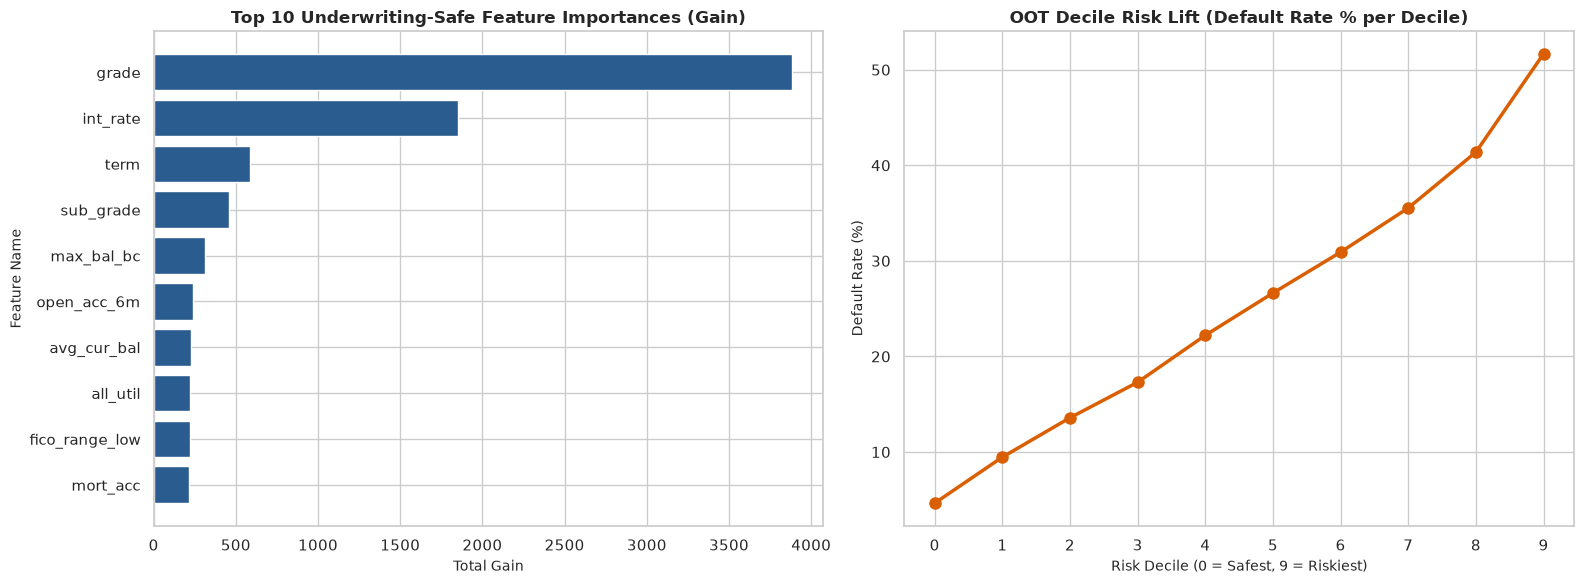

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Top 10 Clean Feature Importances ---
top_10_features = clean_importance_df.head(10).sort_values(by="gain", ascending=True)
axes[0].barh(top_10_features["feature"], top_10_features["gain"], color="#2b5c8f")
axes[0].set_title("Top 10 Underwriting-Safe Feature Importances (Gain)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Total Gain", fontsize=10)
axes[0].set_ylabel("Feature Name", fontsize=10)

# --- Plot 2: Decile Default Rate Lift ---
axes[1].plot(decile_summary['risk_decile'], decile_summary['default_rate'] * 100, marker='o', color='#d95f02', linewidth=2.5, markersize=8)
axes[1].set_title("OOT Decile Risk Lift (Default Rate % per Decile)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Risk Decile (0 = Safest, 9 = Riskiest)", fontsize=10)
axes[1].set_ylabel("Default Rate (%)", fontsize=10)
axes[1].set_xticks(range(10))

plt.tight_layout()
plt.savefig("../reports/model_insights_visualization.png", dpi=300, bbox_inches='tight')
plt.show()

# Phase 6: Portfolio Policy & P&L Simulation

### Objective
Translate our OOT decile risk model into an actionable lending policy simulator. We simulate three credit approval policies:
1. **Conservative Policy:** Block the top 20% highest risk applicants (Deciles 8 & 9).
2. **Balanced Policy (Optimal):** Block the top 30% highest risk applicants (Deciles 7, 8, & 9).
3. **Aggressive Policy:** Block the top 50% highest risk applicants (Deciles 5 through 9).

**Financial Assumptions:**
- Average Loan Amount: $15,000
  
- Loss Given Default (LGD): 70% ($10,500 net loss per default)


- Average 3-Year Interest Margin per Performing Loan: $3,900

Portfolio Policy Financial Simulation Results:
                      Policy  Defaults Prevented  Credit Losses Saved ($M)  Revenue Forfeited ($M)  Net P&L Benefit ($M)
        Baseline (No Filter)                   0                     0.000                  0.0000                0.0000
Conservative (Block Top 20%)                5912                    62.076                 26.5044               35.5716
    Balanced (Block Top 30%)                8170                    85.785                 42.4788               43.3062
  Aggressive (Block Top 50%)               11826                   124.173                 77.7777               46.3953


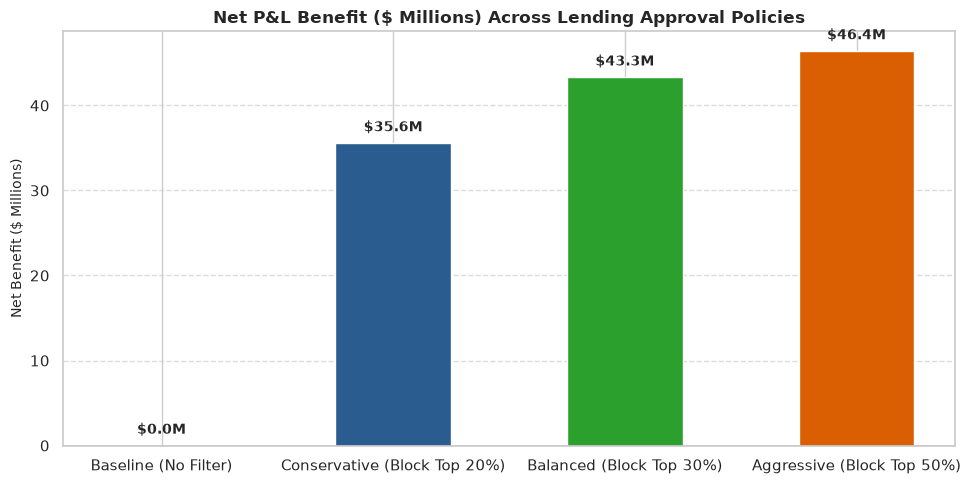

In [22]:
# 1. Financial Assumptions
AVG_LOAN_AMOUNT = 15000
LOSS_GIVEN_DEFAULT = 0.70  # 70% severity
AVG_LOSS_PER_DEFAULT = AVG_LOAN_AMOUNT * LOSS_GIVEN_DEFAULT  # $10,500
AVG_INTEREST_MARGIN = 3900  # $3,900 revenue per performing loan

# 2. Ensure decile_summary is sorted by risk_decile ascending (0 to 9)
sim_df = decile_summary.sort_values(by='risk_decile', ascending=True).copy()

# 3. Define approval policies based on risk decile cutoffs
policies = {
    'Baseline (No Filter)': [],
    'Conservative (Block Top 20%)': [8, 9],
    'Balanced (Block Top 30%)': [7, 8, 9],
    'Aggressive (Block Top 50%)': [5, 6, 7, 8, 9]
}

policy_results = []

for policy_name, blocked_deciles in policies.items():
    if not blocked_deciles:
        blocked_df = sim_df[sim_df['risk_decile'].isin([])]
        approved_df = sim_df
    else:
        blocked_df = sim_df[sim_df['risk_decile'].isin(blocked_deciles)]
        approved_df = sim_df[~sim_df['risk_decile'].isin(blocked_deciles)]
        
    loans_approved = approved_df['total_loans'].sum()
    loans_blocked = blocked_df['total_loans'].sum()
    
    defaults_avoided = blocked_df['defaults'].sum()
    good_rejected = blocked_df['non_defaults'].sum()
    
    credit_losses_saved = defaults_avoided * AVG_LOSS_PER_DEFAULT
    revenue_lost = good_rejected * AVG_INTEREST_MARGIN
    net_benefit = credit_losses_saved - revenue_lost
    
    policy_results.append({
        'Policy': policy_name,
        'Loans Approved': loans_approved,
        'Loans Blocked': loans_blocked,
        'Defaults Prevented': defaults_avoided,
        'Good Loans Rejected': good_rejected,
        'Credit Losses Saved ($M)': credit_losses_saved / 1e6,
        'Revenue Forfeited ($M)': revenue_lost / 1e6,
        'Net P&L Benefit ($M)': net_benefit / 1e6
    })

policy_df = pd.DataFrame(policy_results)
print("Portfolio Policy Financial Simulation Results:")
print(policy_df[['Policy', 'Defaults Prevented', 'Credit Losses Saved ($M)', 'Revenue Forfeited ($M)', 'Net P&L Benefit ($M)']].to_string(index=False))

# 4. Visualize Net P&L Benefit across policies
plt.figure(figsize=(10, 5))
colors = ['#7f7f7f', '#2b5c8f', '#2ca02c', '#d95f02']
bars = plt.bar(policy_df['Policy'], policy_df['Net P&L Benefit ($M)'], color=colors, width=0.5)

plt.title("Net P&L Benefit ($ Millions) Across Lending Approval Policies", fontsize=12, fontweight="bold")
plt.ylabel("Net Benefit ($ Millions)", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.axhline(0, color='black', linewidth=1)

# Add data labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1, f"${height:.1f}M", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig("../reports/portfolio_policy_simulation.png", dpi=300, bbox_inches='tight')
plt.show()

# Phase 7: Granular Feature Drill-Downs & The "Perfect Customer" Profile

### Objective
Extract hard statistical thresholds for our core underwriting drivers:
1. **The DTI Cliff:** Default rates across debt-to-income brackets.
2. **Credit Velocity Thresholds:** Exact risk scaling for new lines opened in the last 6 months (`open_acc_6m`).
3. **The "Perfect Customer" Footprint:** Percentage of total borrowers represented by pristine profiles (Decile 0/1) and the revenue/volume trade-off of targeting only them.

--- SORTED DTI RISK BRACKETS ---
shape: (5, 3)
┌─────────────┬─────────────┬──────────────┐
│ DTI_Bracket ┆ Total_Loans ┆ Default_Rate │
│ ---         ┆ ---         ┆ ---          │
│ cat         ┆ u32         ┆ f64          │
╞═════════════╪═════════════╪══════════════╡
│ 10-20%      ┆ 24366       ┆ 22.560125    │
│ 20-30%      ┆ 16314       ┆ 27.17911     │
│ 30-40%      ┆ 5962        ┆ 32.774237    │
│ <10%        ┆ 15015       ┆ 24.009324    │
│ >40%        ┆ 1882        ┆ 32.146652    │
└─────────────┴─────────────┴──────────────┘

--- 2. Credit Velocity (Open Accounts in Last 6M) ---
shape: (11, 3)
┌─────────────┬─────────────┬──────────────┐
│ open_acc_6m ┆ Total_Loans ┆ Default_Rate │
│ ---         ┆ ---         ┆ ---          │
│ f64         ┆ u32         ┆ f64          │
╞═════════════╪═════════════╪══════════════╡
│ 0.0         ┆ 25393       ┆ 25.034458    │
│ 1.0         ┆ 19938       ┆ 24.666466    │
│ 2.0         ┆ 10537       ┆ 26.221885    │
│ 3.0         ┆ 4727        

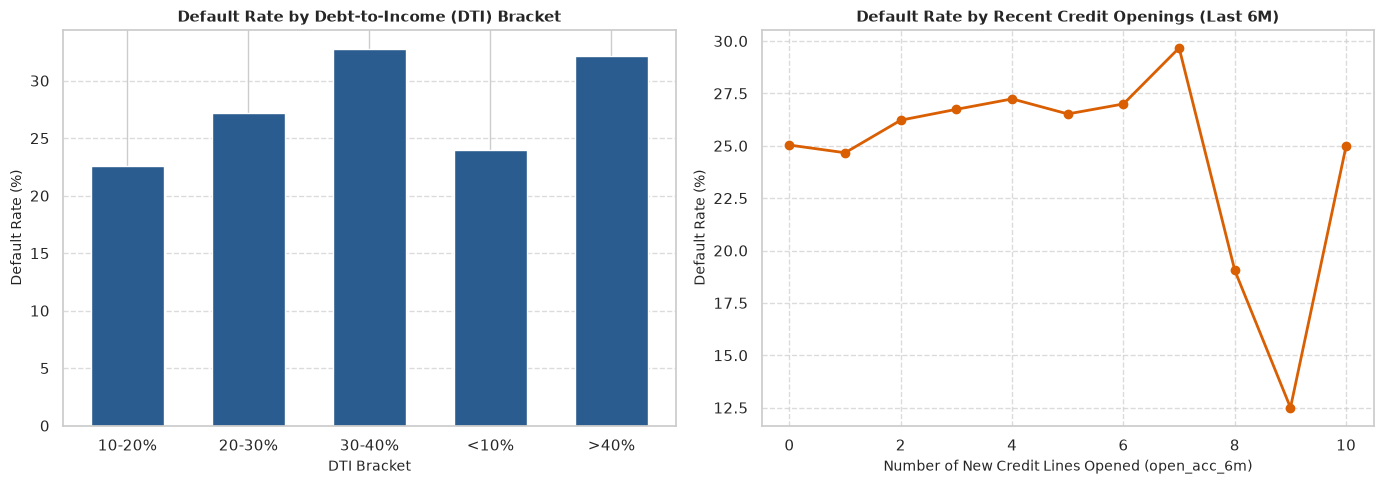

In [36]:
# 1. Ensure binary target exists using Polars expressions
if "target_binary" not in oot_df.columns:
  oot_df = oot_df.with_columns(
      pl.when(
          pl.col("loan_status").is_in(
              ["Charged Off", "Default", "Late (31-120 days)"]
          )
      )
      .then(1)
      .otherwise(0)
      .alias("target_binary")
  )

# Fix DTI sorting by casting to categorical with explicit order
dti_order = ["<10%", "10-20%", "20-30%", "30-40%", ">40%"]

dti_risk_sorted = (
    oot_df.with_columns(
        pl.when(pl.col("dti") <= 10)
        .then(pl.lit("<10%"))
        .when(pl.col("dti") <= 20)
        .then(pl.lit("10-20%"))
        .when(pl.col("dti") <= 30)
        .then(pl.lit("20-30%"))
        .when(pl.col("dti") <= 40)
        .then(pl.lit("30-40%"))
        .otherwise(pl.lit(">40%"))
        .cast(pl.Categorical)
        .alias("DTI_Bracket")
    )
    .group_by("DTI_Bracket")
    .agg([
        pl.len().alias("Total_Loans"),
        (pl.col("target_binary").mean() * 100).alias("Default_Rate"),
    ])
    .sort("DTI_Bracket")
)

print("--- SORTED DTI RISK BRACKETS ---")
print(dti_risk_sorted)

# 3. Credit Velocity Analysis (open_acc_6m) using Polars
velocity_risk = (
    oot_df.filter(pl.col("open_acc_6m") <= 10)
    .group_by("open_acc_6m")
    .agg([
        pl.len().alias("Total_Loans"),
        (pl.col("target_binary").mean() * 100).alias("Default_Rate"),
    ])
    .sort("open_acc_6m")
)

print("\n--- 2. Credit Velocity (Open Accounts in Last 6M) ---")
print(velocity_risk)

# Convert to Pandas for plotting
dti_pd = dti_risk.to_pandas()
vel_pd = velocity_risk.to_pandas()

# 4. Visualizing Feature Risk Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# DTI Chart
axes[0].bar(
    dti_pd["DTI_Bracket"].astype(str),
    dti_pd["Default_Rate"],
    color="#2b5c8f",
    width=0.6,
)
axes[0].set_title(
    "Default Rate by Debt-to-Income (DTI) Bracket", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("DTI Bracket", fontsize=10)
axes[0].set_ylabel("Default Rate (%)", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Credit Velocity Chart
axes[1].plot(
    vel_pd["open_acc_6m"],
    vel_pd["Default_Rate"],
    marker="o",
    color="#d95f02",
    linewidth=2,
    markersize=6,
)
axes[1].set_title(
    "Default Rate by Recent Credit Openings (Last 6M)",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel(
    "Number of New Credit Lines Opened (open_acc_6m)", fontsize=10
)
axes[1].set_ylabel("Default Rate (%)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig("../reports/feature_drilldown_insights.png", dpi=300, bbox_inches="tight")
plt.show()